### This cell will be used to create data that will help machine learning model to predict the proper batches! 

In [56]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt

In [38]:
## Creating the dataframe
lunch_time = np.arange(0, 121, 1)
print(lunch_time)

[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119 120]


### Creating Scenarios : 
#### Slow rush overall 
1. 1 students / minute -> outside rush 
2. 3 students / minute -> inside rush 
### Normal rush overall 
1. 2 students / minute -> outside rush 
2. 5 students / minute -> inside rush 
### Busy rush overall 
1. 3 students / minute -> outside rush 
2. 7 students / minute -> inside rush 

In [ ]:
rng = np.random.default_rng(42) ## to regenerate the same sample
lunches = []
for i in range(25):
    slow_0 = pd.DataFrame({"minute": np.arange(1, 121),"rate": 1}) ## Total 120 minutes information 
    slow_0.loc[slow_0["minute"].between(1, 30), "rate"] = 3 ## Between the 60-90 minute rush is seen 
    slow_0["arrivals"] = rng.poisson(slow_0["rate"]) ## Poission distirbution where the rate will be maintained
    slow_0["last_5_min"] = (slow_0["arrivals"].rolling(5, min_periods=1).sum()) ## Cumulative sum for first 5
    slow_0["last_10_min"] = (slow_0["arrivals"].rolling(10, min_periods=1).sum()) ## Cumulative sum for first 10 
    slow_0["type"] = "slow" ## Type of rush 
    slow_0['next_10_min'] = slow_0["arrivals"].rolling(10).sum().shift(-10)
    lunches.append(slow_0)
for i in range(25): 
    slow_60 = pd.DataFrame({"minute": np.arange(1, 121),"rate": 1}) ## Total 120 minutes information 
    slow_60.loc[slow_60["minute"].between(61, 90), "rate"] = 3 ## Between the 60-90 minute rush is seen 
    slow_60["arrivals"] = rng.poisson(slow_60["rate"]) ## Poission distirbution where the rate will be maintained
    slow_60["last_5_min"] = (slow_60["arrivals"].rolling(5, min_periods=1).sum()) ## Cumulative sum for first 5
    slow_60["last_10_min"] = (slow_60["arrivals"].rolling(10, min_periods=1).sum()) ## Cumulative sum for first 10 
    slow_60["type"] = "slow" ## Type of rush 
    slow_60['next_10_min'] = slow_60["arrivals"].rolling(10).sum().shift(-10)
    lunches.append(slow_60)

for i in range(25):
    slow_30 = pd.DataFrame({"minute": np.arange(1, 121),"rate": 1}) ## Total 120 minutes information 
    slow_30.loc[slow_30["minute"].between(31, 60), "rate"] = 3 ## Between the 60-90 minute rush is seen 
    slow_30["arrivals"] = rng.poisson(slow_30["rate"]) ## Poission distirbution where the rate will be maintained
    slow_30["last_5_min"] = (slow_30["arrivals"].rolling(5, min_periods=1).sum()) ## Cumulative sum for first 5
    slow_30["last_10_min"] = (slow_30["arrivals"].rolling(10, min_periods=1).sum()) ## Cumulative sum for first 10 
    slow_30["type"] = "slow" ## Type of rush 
    slow_30['next_10_min'] = slow_30["arrivals"].rolling(10).sum().shift(-10)
    lunches.append(slow_30)

for i in range(25):
    slow_90 = pd.DataFrame({"minute": np.arange(1, 121),"rate": 1}) ## Total 120 minutes information 
    slow_90.loc[slow_90["minute"].between(91, 120), "rate"] = 3 ## Between the 60-90 minute rush is seen 
    slow_90["arrivals"] = rng.poisson(slow_90["rate"]) ## Poission distirbution where the rate will be maintained
    slow_90["last_5_min"] = (slow_90["arrivals"].rolling(5, min_periods=1).sum()) ## Cumulative sum for first 5
    slow_90["last_10_min"] = (slow_90["arrivals"].rolling(10, min_periods=1).sum()) ## Cumulative sum for first 10 
    slow_90["type"] = "slow" ## Type of rush 
    slow_90['next_10_min'] = slow_90["arrivals"].rolling(10).sum().shift(-10)
    lunches.append(slow_90)
slow_data = pd.concat(lunches, ignore_index=True)
slow_data.head(10)



,minute,rate,arrivals,last_5_min,last_10_min,type,next_10_min
0,1,3,4,4.0,4.0,slow,35.0
1,2,3,4,8.0,8.0,slow,32.0
2,3,3,5,13.0,13.0,slow,33.0
3,4,3,1,14.0,14.0,slow,34.0
4,5,3,7,21.0,21.0,slow,32.0
5,6,3,1,18.0,22.0,slow,31.0
6,7,3,4,18.0,26.0,slow,29.0
7,8,3,2,15.0,28.0,slow,29.0
8,9,3,2,16.0,30.0,slow,30.0
9,10,3,5,14.0,35.0,slow,29.0


minute
1      1.48
2      1.64
3      1.27
4      1.42
5      1.55
6      1.55
7      1.59
8      1.41
9      1.37
10     1.36
11     1.55
12     1.56
13     1.43
14     1.58
15     1.42
16     1.47
17     1.72
18     1.49
19     1.52
20     1.58
21     1.59
22     1.36
23     1.33
24     1.61
25     1.37
26     1.71
27     1.58
28     1.44
29     1.58
30     1.50
31     1.59
32     1.58
33     1.26
34     1.62
35     1.36
36     1.61
37     1.47
38     1.49
39     1.47
40     1.72
41     1.52
42     1.53
43     1.59
44     1.56
45     1.70
46     1.55
47     1.57
48     1.35
49     1.42
50     1.43
51     1.55
52     1.61
53     1.45
54     1.55
55     1.56
56     1.38
57     1.33
58     1.26
59     1.42
60     1.48
61     1.45
62     1.42
63     1.50
64     1.72
65     1.64
66     1.53
67     1.60
68     1.58
69     1.87
70     1.39
71     1.59
72     1.56
73     1.45
74     1.55
75     1.42
76     1.52
77     1.59
78     1.69
79     1.44
80     1.42
81     1.76
82     1.65
83     1.

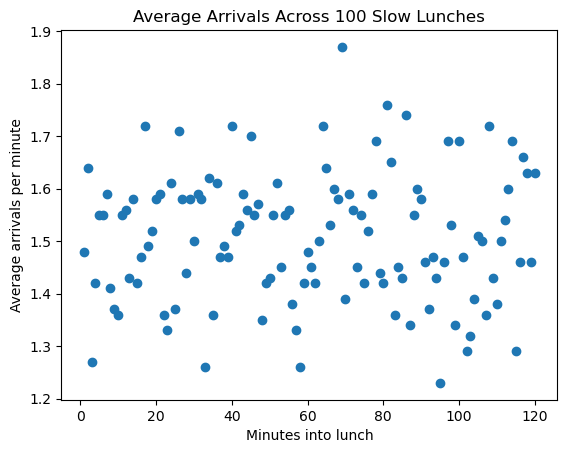

In [70]:
a = slow_data.groupby("minute")["arrivals"].mean()

print(a.to_string())

plt.scatter(a.index, a.values)
plt.xlabel("Minutes into lunch")
plt.ylabel("Average arrivals per minute")
plt.title("Average Arrivals Across 100 Slow Lunches")
plt.show()